# Exploratory Data Analysis on the Titanic Dataset

## 1. Project Overview

This project explores the Titanic passenger dataset using Python.
The analysis focuses on data quality, passenger characteristics,
survival rates, and relationships between selected variables.

## 2. Dataset

The dataset contains passenger information and a survival outcome.
The analysis uses the labeled training dataset from Kaggle.

## 3. Tools and Libraries

- Python
- Pandas
- Matplotlib
- Seaborn


## Import Libraries and visvisualization Configuration

Import the libraries required for data manipulation,
statistical exploration, and visualization Configuration by apply a consistent plotting style and configure the default
figure size for readable charts.

In [109]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

## Load the Dataset

Load the CSV file into a Pandas DataFrame.
A DataFrame is a table-like structure containing rows and columns and Display the first five rows to understand the dataset's columns, values, and general structure.

In [110]:
df = pd.read_csv('train.csv')   
print("Dataset loaded successfully.")
df.head()

Dataset loaded successfully.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Dataset Dimensions, information and Duplicate Records

Determine the number of observations and variables and reviewing column data types, non-missing value counts,
and memory usage in a single summary.

Also checking whether any rows are duplicated across all columns.

In [111]:
print('Shape (rows, columns):', df.shape)
print('Duplicate rows:', df.duplicated().sum())
df.info()

Shape (rows, columns): (891, 12)
Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## Data Quality Assessment 

Calculate the number and percentage of missing values
in each column before deciding how to handle them.

In [112]:
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing %': (df.isnull().mean() * 100).round(2)
}).sort_values('Missing %', ascending=False)

missing_summary

,Missing Values,Missing %
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


### Missing-Value Visualization

Use a heatmap to examine the distribution of missing
values across rows and columns.

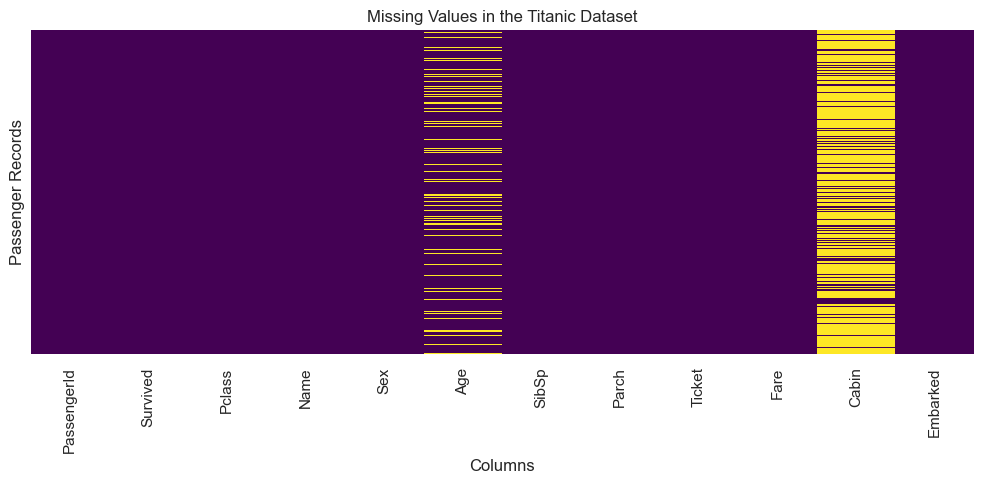

In [113]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Values in the Titanic Dataset')
plt.xlabel('Columns')
plt.ylabel('Passenger Records')
plt.tight_layout()
plt.show()

### Data Cleaning

Before cleaning the dataset, this is what each column means.

- **Age:** Fill missing values with the median. This preserves all rows, and the median is less affected by extreme ages than the mean.

- **Embarked:** Fill missing values with the mode (the most frequently occurring port). Only two values are missing, so using the most common port is a reasonable approach.

- **Cabin:** Drop this column because approximately 77% of its values are missing. Filling in so many missing values would require making unsupported assumptions.

- **PassengerId, Name, and Ticket:** Drop these columns because they are primarily identifiers or individual details that are not needed for the planned analysis. The goal is to focus on the features relevant to understanding passenger survival.

### Create a Working Copy

Create a copy of the original dataset so cleaning operations
do not modify the raw data.

In [114]:
df_clean = df.copy()

### Handle missing values
-Replace missing age values with the median of the observed ages.
-Fill missing port values with the most frequently recorded port.
-Dropping Cabin, PassengerId, Name, Ticket from the working DataFrame.

In [115]:
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])
df_clean = df_clean.drop(columns=['Cabin', 'PassengerId', 'Name', 'Ticket'])

### Convert Data Types

Convert `Sex` and `Embarked` to the `category` data type because they contain a small, fixed set of values. Keep `Survived` and `Pclass` as integers because they are needed for calculating survival rates and numerical correlation analysis.

In [116]:
df_clean['Sex'] = df_clean['Sex'].astype('category')
df_clean['Embarked'] = df_clean['Embarked'].astype('category')

### Verify and Validate the Cleaned Dataset

Recheck missing values to confirm the cleaning results and identify any remaining missing data. Review the dataset's structure and descriptive statistics to ensure the data is consistent and ready for analysis.

In [117]:
print(df_clean.isnull().sum())
print()
df_clean.info()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   Survived  891 non-null    int64   
 1   Pclass    891 non-null    int64   
 2   Sex       891 non-null    category
 3   Age       891 non-null    float64 
 4   SibSp     891 non-null    int64   
 5   Parch     891 non-null    int64   
 6   Fare      891 non-null    float64 
 7   Embarked  891 non-null    category
dtypes: category(2), float64(2), int64(4)
memory usage: 43.7 KB


## Summary Statistics
## Descriptive Statistics

Calculate descriptive statistics to understand the distribution
of numerical variables, including age, fare, and family counts.

In [118]:
df_clean.describe()


,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Survival Distribution and Overall Survival Rate

Count the passengers who survived and did not survive, then calculate the overall survival rate as the proportion of passengers who survived.

In [119]:
for col in ['Survived', 'Pclass', 'Sex', 'Embarked']:
    print(df_clean[col].value_counts())
    print()

overall_survival_rate = df_clean['Survived'].mean() * 100
print(f'Overall survival rate: {overall_survival_rate:.2f}%')

Survived
0    549
1    342
Name: count, dtype: int64

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Sex
male      577
female    314
Name: count, dtype: int64

Embarked
S    646
C    168
Q     77
Name: count, dtype: int64

Overall survival rate: 38.38%


### Group-based analysis
### Reusable Survival-Rate Function

Define a reusable function that groups passengers by a specified column and calculates each group's survival rate as a percentage.

-`groupby()` method separates passengers into groups, 
 
-`mean()` calculates the survival proportion, 
 
-`mul(100)` converts it to a percentage rounded to two decimal places.

In [120]:
def survival_rate(data, by):
    return (data.groupby(by, observed=True)['Survived']
                .mean().mul(100).round(2)
                .reset_index(name='Survival Rate (%)'))

## Survival Analysis by Passenger Group

### Survival Rate by Sex and Passenger Class

Group passengers by recorded sex and calculate the mean
of the binary survival variable for each group and comparing survival proportions across first-, second-,
and third-class passengers.

In [121]:
survival_by_sex = survival_rate(df_clean, 'Sex')
survival_by_class = survival_rate(df_clean, 'Pclass')


display(survival_by_sex)
display(survival_by_class)


,Sex,Survival Rate (%)
0,female,74.20
1,male,18.89


,Pclass,Survival Rate (%)
0,1,62.96
1,2,47.28
2,3,24.24


### Survival Rate by Sex and Passenger Class

Examine how the survival rate differs when passengers
are grouped by both sex and passenger class.

In [122]:
survival_by_sex_class = survival_rate(df_clean, ['Sex', 'Pclass'])
display(survival_by_sex_class)

,Sex,Pclass,Survival Rate (%)
0,female,1,96.81
1,female,2,92.11
2,female,3,50.00
3,male,1,36.89
4,male,2,15.74
5,male,3,13.54


### Survival Rate by Age Group

Create age categories and compare the survival rates
across those categories.

In [123]:
df_clean['AgeGroup'] = pd.cut(
    df_clean['Age'],
    bins=[0, 12, 18, 35, 60, 120],
    labels=['0-12', '13-18', '19-35', '36-60', '61+'],
    include_lowest=True
)

survival_by_age = survival_rate(df_clean, 'AgeGroup')
survival_by_age

,AgeGroup,Survival Rate (%)
0,0-12,57.97
1,13-18,42.86
2,19-35,35.33
3,36-60,40.00
4,61+,22.73


### Survival Counts by Passenger Class

Compare the number of survivors and non-survivors
within each passenger class.

In [124]:
pd.crosstab(df_clean['Pclass'], df_clean['Survived'],
            rownames=['Passenger Class'],
            colnames=['Survived (0 = No, 1 = Yes)'])

"Survived (0 = No, 1 = Yes)",0,1
Passenger Class,,
1,80,136
2,97,87
3,372,119


## Data Visualization

### Overall Survival Distribution

Visualize the number of passengers who survived and
did not survive.

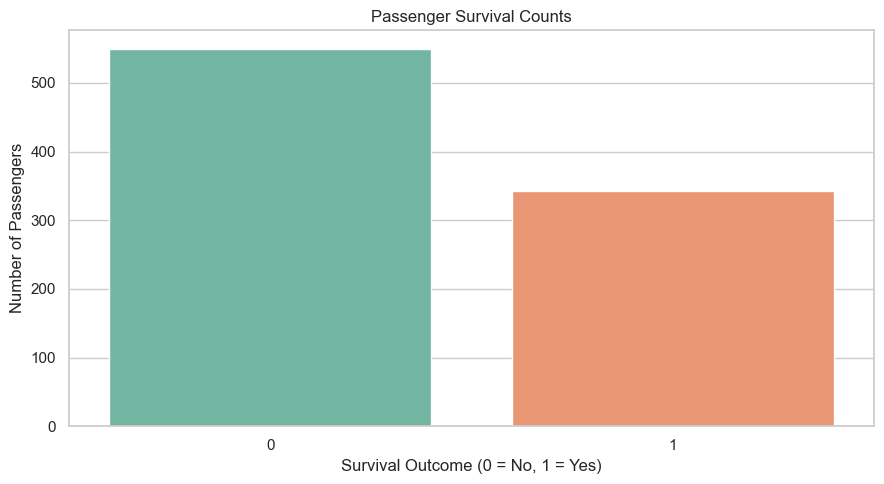

In [125]:
sns.countplot(data=df_clean, x='Survived', hue='Survived', palette='Set2', legend=False)
plt.title('Passenger Survival Counts')
plt.xlabel('Survival Outcome (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')
plt.tight_layout()
plt.show()

### Survival Rate by Sex

Compare the percentage of passengers who survived
within each recorded sex category.

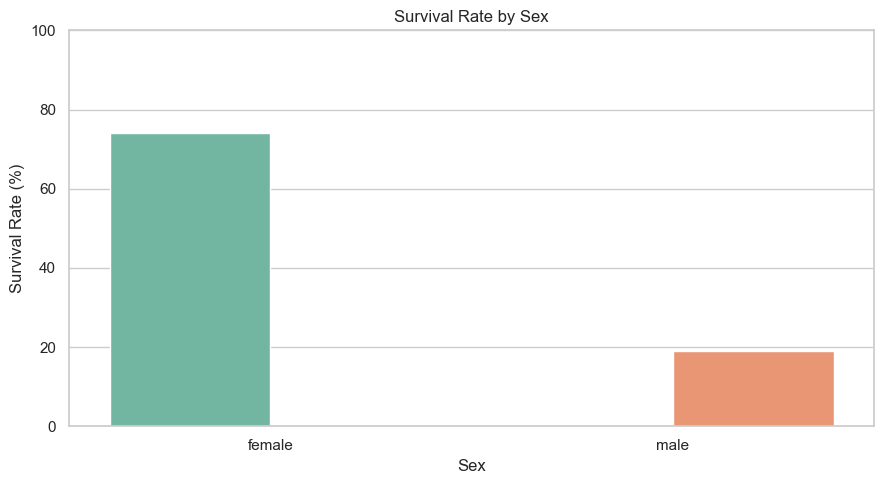

In [126]:
sns.barplot(data=survival_by_sex, x='Sex', y='Survival Rate (%)', hue='Sex', palette='Set2', legend=False)
plt.title('Survival Rate by Sex')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Survival Rate by Passenger Class

Compare the percentage of passengers who survived
in each passenger class.

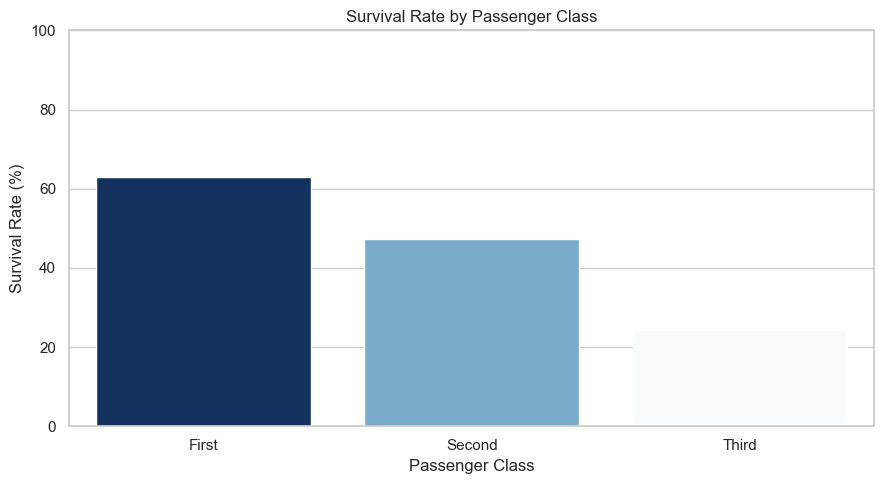

In [133]:
sns.barplot(data=survival_by_class, x='Pclass', y='Survival Rate (%)', hue='Pclass', palette='Blues_r', legend=False)
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.xticks([0, 1, 2], ['First', 'Second', 'Third'])
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Survival Rate by Sex and Passenger Class

Compare survival percentages across combinations of sex
and passenger class.

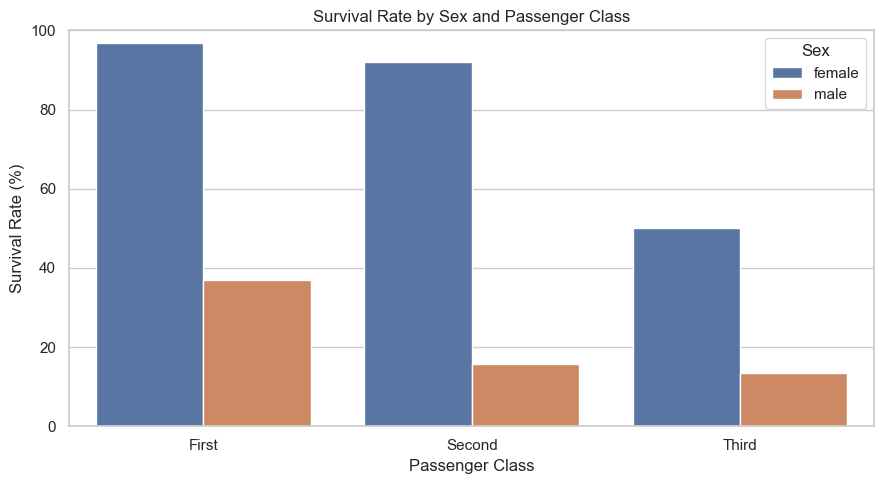

In [128]:
sns.barplot(data=survival_by_sex_class, x='Pclass', y='Survival Rate (%)', hue='Sex')
plt.title('Survival Rate by Sex and Passenger Class')
plt.xlabel('Passenger Class')
plt.xticks([0, 1, 2], ['First', 'Second', 'Third'])
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Step 9.5 — Age Distribution and Survival by Age Group

Visualize the distribution of passenger ages and compare survival rates across age groups. 

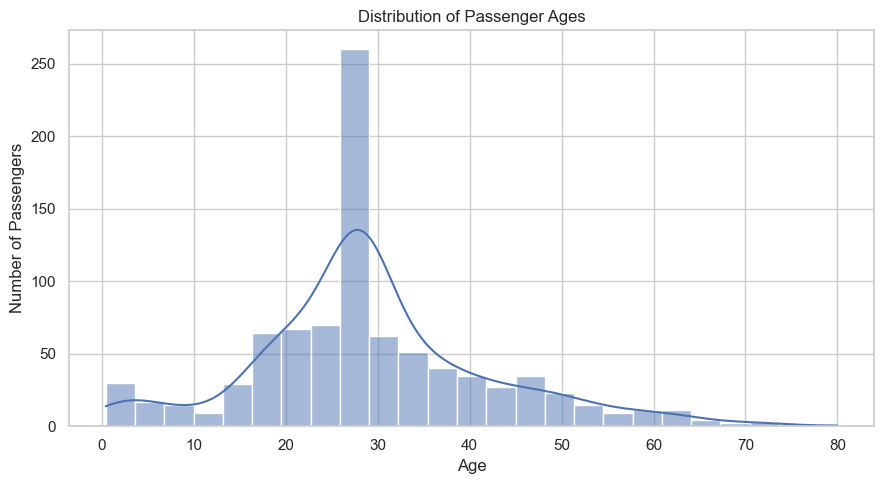

In [129]:
sns.histplot(data=df_clean, x='Age', bins=25, kde=True)
plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.tight_layout()
plt.show()

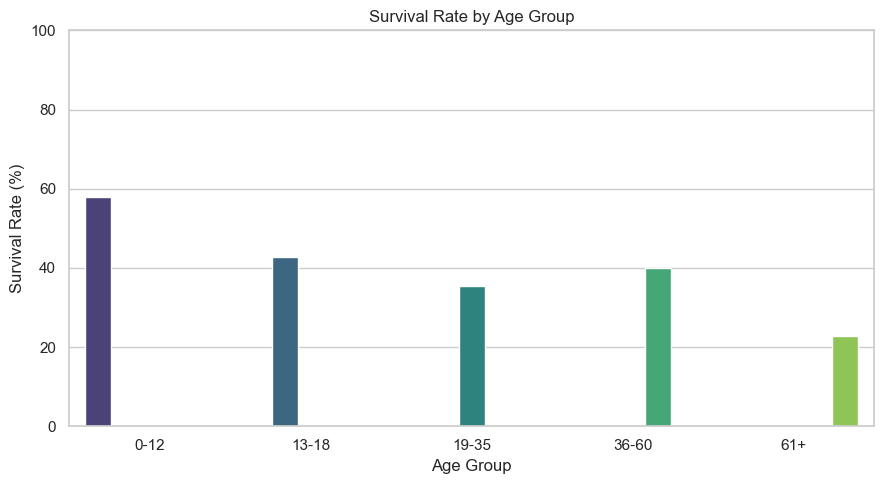

In [130]:
sns.barplot(data=survival_by_age, x='AgeGroup', y='Survival Rate (%)', hue='AgeGroup', palette='viridis', legend=False)
plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Survival Rate Heatmap (bonus)

Visualize survival percentages across sex and passenger class.

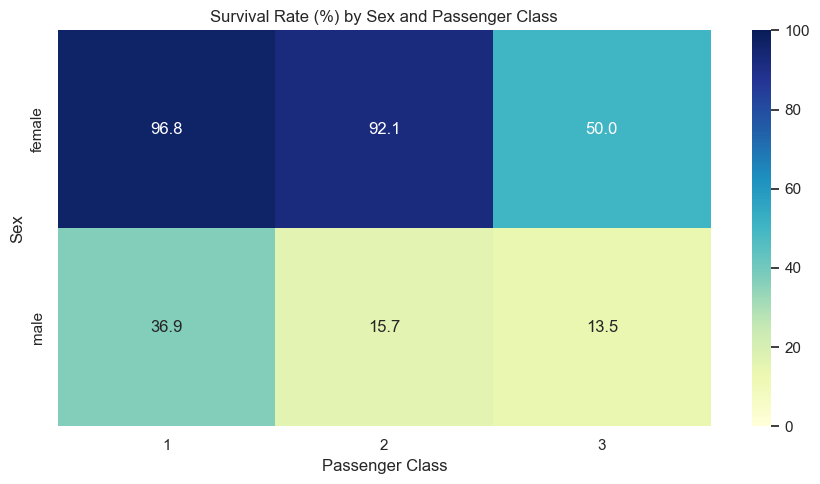

In [131]:
heatmap_data = df_clean.pivot_table(values='Survived', index='Sex', columns='Pclass',
                                    aggfunc='mean', observed=True) * 100

sns.heatmap(heatmap_data, annot=True, fmt='.1f', cmap='YlGnBu', vmin=0, vmax=100)
plt.title('Survival Rate (%) by Sex and Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Sex')
plt.tight_layout()
plt.show()

### Correlation Analysis

Examine correlations between selected numerical variables
to identify potential linear relationships.

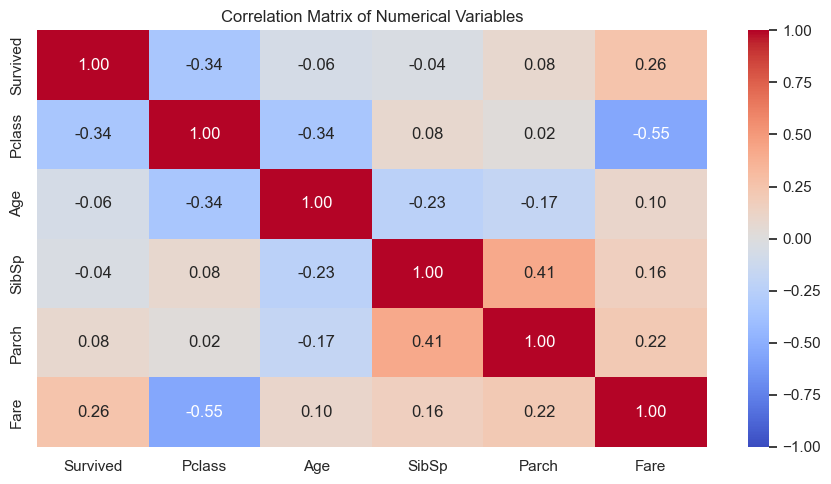

In [132]:
numeric_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

sns.heatmap(df_clean[numeric_cols].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

## 10. Findings, Limitations and Conclusion

### Key Findings

1. **Overall survival:** The overall survival rate was **38.38%** (342 out of 891 passengers), while 549 passengers (61.62%) did not survive.

2. **Survival by sex:** Female passengers had a survival rate of **74.20%**, compared with **18.89%** for male passengers, showing a substantial difference between the two groups.

3. **Survival by passenger class:** First-class passengers had the highest survival rate at **62.96%**, followed by second-class passengers at **47.28%** and third-class passengers at **24.24%**.

4. **Survival by sex and class:** Female passengers had higher survival rates than males across all classes. The highest rate was **96.81%** among first-class females, while third-class males had the lowest rate at **13.54%**.

5. **Survival by age group:** Children aged 0–12 had the highest survival rate at **57.97%**, followed by passengers aged 36–60 at 40.00%, those aged 13–18 at 42.86%, and those aged 19–35 at 35.33%. Passengers aged 61 and above had the lowest rate at **22.73%**.

6. **Correlation with survival:** `Pclass` had the strongest numerical correlation with survival at **-0.338**, followed by `Fare` at **0.257**. The negative correlation indicates that higher class numbers, representing lower passenger classes, were associated with lower survival. The remaining numerical variables had weaker correlations with survival.

7. **Data quality:** The original dataset contained missing values in `Age`, `Embarked`, and `Cabin`. Missing ages were filled using the median, missing embarkation ports using the mode, and `Cabin` was removed because approximately 77% of its values were missing. Unnecessary identifier columns were also removed. The cleaned dataset contained **891 rows and 9 columns**, with no remaining missing values.

### Limitations

- Missing ages and embarkation ports were filled using the median and mode, respectively. These methods introduce assumptions and may affect the results.
- The `Cabin` column was excluded because approximately 77% of its values were missing, potentially removing useful information.
- The analysis describes only the passengers represented in this dataset and should not be generalized beyond its scope.
- Correlation measures association rather than causation. Variables such as passenger class, fare, sex, and age may overlap in their relationship with survival.
- Missing ages filled with the median may create an artificial concentration around the median age and affect the observed age distribution.

### Conclusion

This exploratory data analysis examined passenger survival patterns using demographic characteristics, passenger class, and other numerical variables. The overall survival rate was **38.38%**, with higher survival rates among females, first-class passengers, and children aged 0–12. Passenger class showed the strongest numerical correlation with survival, followed by fare, although these relationships do not establish causation. Further analysis could use statistical tests or predictive models to investigate the combined influence of passenger characteristics on survival.